In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [27]:
df = pd.read_csv("customers.csv")

print(df.head())
print(df.shape)
print(df.info())
df.columns

   CustomerID   Genre  Age  Annual_Income  Spending_Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40
(16, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      16 non-null     int64 
 1   Genre           16 non-null     object
 2   Age             16 non-null     int64 
 3   Annual_Income   16 non-null     int64 
 4   Spending_Score  16 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 772.0+ bytes
None


Index(['CustomerID', 'Genre', 'Age', 'Annual_Income', 'Spending_Score'], dtype='object')

In [28]:
print(df.isnull().sum())

df = df.dropna()

print("Dataset after cleaning:")
print(df.shape)

CustomerID        0
Genre             0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64
Dataset after cleaning:
(16, 5)


In [29]:

df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

In [30]:
X = df[['Annual_Income', 'Spending_Score']]


In [31]:
X = StandardScaler().fit_transform(X)


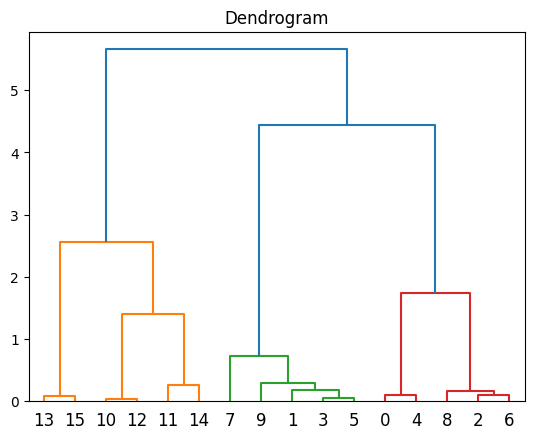

In [32]:
Z = linkage(X, method='ward')
dendrogram(Z)
plt.title("Dendrogram")
plt.show()


In [33]:
# Apply clustering
model = AgglomerativeClustering(n_clusters=5)
df['Cluster'] = model.fit_predict(X)


In [34]:
print(df[['CustomerID', 'Cluster']].head())
print(df['Cluster'].value_counts())


   CustomerID  Cluster
0           1        4
1           2        2
2           3        1
3           4        2
4           5        4
Cluster
2    5
0    4
1    3
4    2
3    2
Name: count, dtype: int64


In [37]:
print("Cluster-wise Average:")

print(
    df.groupby('Cluster')[
        ['Annual_Income', 'Spending_Score']
    ].mean()
)

Cluster-wise Average:
         Annual_Income  Spending_Score
Cluster                               
0            60.250000           29.75
1            17.666667            5.00
2            17.000000           80.00
3            60.500000           78.00
4            16.000000           39.50


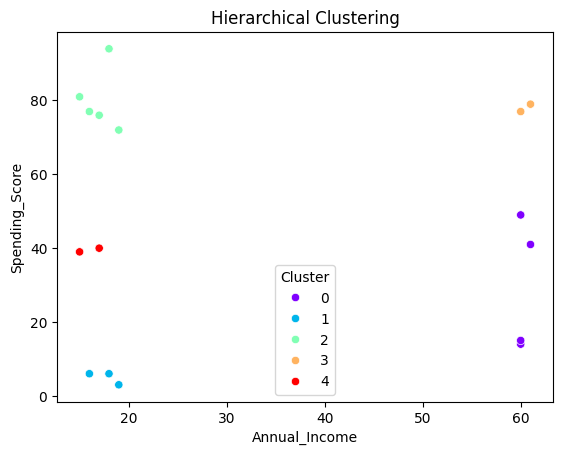

In [38]:
sns.scatterplot(
    x=df['Annual_Income'],
    y=df['Spending_Score'],
    hue=df['Cluster'],
    palette='rainbow'
)

plt.title("Hierarchical Clustering")
plt.show()